# Fraud Detection with Time-Based Hyperparameter Search

This notebook compares logistic regression, a decision tree, random forest, and XGBoost for prioritizing transaction reviews. The operating policy reviews the highest-scoring **5% of transactions**, rather than using a probability threshold of 0.5.

## Workflow
1. Load public transaction data and validate field types.
2. Split chronologically into approximately 60% training, 20% validation, and 20% test.
3. Tune hyperparameters using three expanding time folds within training only.
4. Refit each selected configuration on the same balanced sample of the full training period.
5. Compare model families on outer validation, then evaluate the selected model on test.

**Search scope:** six logistic-regression C values are evaluated exhaustively. The tree models use limited randomized search over discrete parameter grids, with 6, 8, and 10 candidates, respectively, including their baseline configurations. This is **30 configurations and 90 fold fits**, not exhaustive grid search across all model families. No early stopping is used.

**Execution note:** model outputs below are preserved from the previously executed notebook; this cleaned version has not been rerun end to end. Newly added setup and training-only EDA cells have no saved outputs. Package versions from the historical run were not recorded; rerunning under a different environment may change results. Run cells from top to bottom.

**Data:** [Capital One recruiting data challenge](https://github.com/CapitalOneRecruiting/DS). This is public challenge data, not OneMain customer data. Download the source data separately; this notebook does not embed transaction-level records.

## 1. Environment and data loading
Install dependencies in your environment if needed:
```bash
python -m pip install numpy pandas matplotlib scikit-learn imbalanced-learn xgboost requests jupyter
```
A local `data/transactions.txt` is used when available. Otherwise, the loader downloads the public ZIP archive. No account identifiers or raw CVV values are displayed in notebook outputs.

In [1]:
from pathlib import Path
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from importlib.metadata import version

# Record versions for future reproducibility.
for package in ["numpy", "pandas", "scikit-learn", "imbalanced-learn", "xgboost"]:
    print(f"{package}: {version(package)}")

local_data = Path("data/transactions.txt")
if local_data.exists():
    transactions = pd.read_json(local_data, lines=True)
else:
    data_url = "https://github.com/CapitalOneRecruiting/DS/raw/master/transactions.zip"
    response = requests.get(data_url, timeout=120)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        with archive.open("transactions.txt") as data_file:
            transactions = pd.read_json(data_file, lines=True)

print(f"Loaded {len(transactions):,} transactions and {transactions.shape[1]} fields.")
transactions_copy = transactions.copy()
transactions_copy = transactions_copy.replace(["", " ", "N/A", "NULL"], np.nan)

numpy: 2.0.2
pandas: 2.3.3
scikit-learn: 1.6.1
imbalanced-learn: 0.12.4
xgboost: 2.1.4
Loaded 786,363 transactions and 29 fields.


C:\Users\82434\AppData\Local\Temp\ipykernel_33720\4097647009.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  transactions_copy = transactions_copy.replace(["", " ", "N/A", "NULL"], np.nan)


## 2. Field validation and feature definition
Use thirteen inputs: six categorical fields, four numeric fields, and three binary indicators. CVV mismatch is engineered without passing raw CVV values into the model. Missing source CVVs produce a missing indicator.

Identifiers and timestamps are excluded from model inputs. Column selection also excludes unused and entirely empty fields. Large transactions and repeated-looking transactions are not automatically removed. Balance fields require an availability audit before deployment: their values must be known at scoring time. The feature set stays fixed throughout hyperparameter search.

In [2]:
import numpy as np
import pandas as pd

# Convert empty or whitespace-only strings to missing values.
transactions_copy = transactions_copy.replace(r"^\s*$", np.nan, regex=True)

# Use timestamps for sorting and splitting, not as model inputs.
transactions_copy["transactionDateTime"] = pd.to_datetime(
    transactions_copy["transactionDateTime"],
    errors="raise"
)

if transactions_copy["transactionDateTime"].isna().any():
    raise ValueError("Missing transactionDateTime values must be investigated.")

# Normalize Boolean and equivalent string values to 0/1.
binary_mapping = {
    "true": 1,
    "false": 0,
    "1": 1,
    "0": 0,
    "1.0": 1,
    "0.0": 0,
}

for col in ["cardPresent", "expirationDateKeyInMatch", "isFraud"]:
    original = transactions_copy[col]
    converted = (
        original.astype("string")
        .str.strip()
        .str.lower()
        .map(binary_mapping)
    )

    invalid = original.notna() & converted.isna()
    if invalid.any():
        raise ValueError(
            f"{col} contains unrecognized values: "
            f"{original.loc[invalid].unique()[:10]}"
        )

    transactions_copy[col] = converted

# Target labels must not be missing.
if transactions_copy["isFraud"].isna().any():
    raise ValueError("Missing isFraud values must be investigated.")

transactions_copy["isFraud"] = transactions_copy["isFraud"].astype(int)

# Engineer a CVV mismatch indicator.
# Keep the indicator missing if either CVV is unavailable; impute during training.
cvv_available = (
    transactions_copy["cardCVV"].notna()
    & transactions_copy["enteredCVV"].notna()
)

transactions_copy["cvv_mismatch"] = np.nan

transactions_copy.loc[cvv_available, "cvv_mismatch"] = (
    transactions_copy.loc[cvv_available, "cardCVV"]
    != transactions_copy.loc[cvv_available, "enteredCVV"]
).astype(int)

In [3]:
cat_features = [
    "merchantCountryCode",
    "merchantCategoryCode",
    "posConditionCode",
    "posEntryMode",
    "transactionType",
    "acqCountry",
]

num_features = [
    "creditLimit",
    "availableMoney",
    "transactionAmount",
    "currentBalance",
]

binary_features = [
    "cardPresent",
    "expirationDateKeyInMatch",
    "cvv_mismatch",
]

features = cat_features + num_features + binary_features

# Validate and convert numeric feature types.
for col in num_features:
    transactions_copy[col] = pd.to_numeric(
        transactions_copy[col],
        errors="raise"
    )

## 3. Chronological train / validation / test split
Identical timestamps remain within one split. Customers may recur across periods: this evaluates future transactions, not exclusively unseen customers. The outer validation set selects the model family; internal time folds select hyperparameters.

In [4]:
transactions_copy = (
    transactions_copy
    .sort_values("transactionDateTime", kind="stable")
    .reset_index(drop=True)
)

n = len(transactions_copy)

train_end = int(n * 0.60)
valid_end = int(n * 0.80)

# If a boundary falls within a group of identical timestamps,
# place that entire timestamp group in the later split.
timestamps = transactions_copy["transactionDateTime"]

train_end = int(timestamps.searchsorted(
    timestamps.iloc[train_end], side="left"
))
valid_end = int(timestamps.searchsorted(
    timestamps.iloc[valid_end], side="left"
))

train_df = transactions_copy.iloc[:train_end].copy()
valid_df = transactions_copy.iloc[train_end:valid_end].copy()
test_df = transactions_copy.iloc[valid_end:].copy()

# Retain training timestamps for time-based cross-validation.
train_times = train_df["transactionDateTime"].reset_index(drop=True)

X_train = train_df[features].reset_index(drop=True)
y_train = train_df["isFraud"].reset_index(drop=True)

X_valid = valid_df[features].reset_index(drop=True)
y_valid = valid_df["isFraud"].reset_index(drop=True)

X_test = test_df[features].reset_index(drop=True)
y_test = test_df["isFraud"].reset_index(drop=True)

assert train_df["transactionDateTime"].max() < valid_df["transactionDateTime"].min()
assert valid_df["transactionDateTime"].max() < test_df["transactionDateTime"].min()

In [5]:
for name, data in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df),
]:
    print(
        f"{name}: "
        f"n={len(data):,}, "
        f"fraud_count={data['isFraud'].sum():,}, "
        f"fraud_rate={data['isFraud'].mean():.2%}"
    )
    print(
        f"Time range: "
        f"{data['transactionDateTime'].min()} "
        f"to {data['transactionDateTime'].max()}\n"
    )

print("Training feature missing values:")
print(X_train.isna().sum())

print("\nTraining feature types:")
print(X_train.dtypes)

Train: n=471,817, fraud_count=7,753, fraud_rate=1.64%
Time range: 2016-01-01 00:01:02 to 2016-08-13 06:55:08

Validation: n=157,273, fraud_count=2,351, fraud_rate=1.49%
Time range: 2016-08-13 06:55:56 to 2016-10-23 01:50:20

Test: n=157,273, fraud_count=2,313, fraud_rate=1.47%
Time range: 2016-10-23 01:52:26 to 2016-12-30 23:59:45

Training feature missing values:
merchantCountryCode          444
merchantCategoryCode           0
posConditionCode             258
posEntryMode                2444
transactionType              417
acqCountry                  2838
creditLimit                    0
availableMoney                 0
transactionAmount              0
currentBalance                 0
cardPresent                    0
expirationDateKeyInMatch       0
cvv_mismatch                   0
dtype: int64

Training feature types:
merchantCountryCode          object
merchantCategoryCode         object
posConditionCode             object
posEntryMode                 object
transactionType       

## 4. Training-only exploratory analysis
The following summaries describe the original training period before undersampling. They are descriptive associations, not causal effects. Missing-value handling is learned later within each training fold.

,missing_count,missing_percent
acqCountry,2838,0.601504
posEntryMode,2444,0.517997
merchantCountryCode,444,0.094104
transactionType,417,0.088382
posConditionCode,258,0.054682
merchantCategoryCode,0,0.000000
creditLimit,0,0.000000
availableMoney,0,0.000000
transactionAmount,0,0.000000
currentBalance,0,0.000000


,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,464064.0,138.440434,147.385361,0.0,34.68,90.79,193.63,2011.54
1,7753.0,227.151813,189.960558,0.0,86.71,178.22,312.77,1608.35


,size,mean
cardPresent,,
0,259523,0.021582
1,212294,0.010137


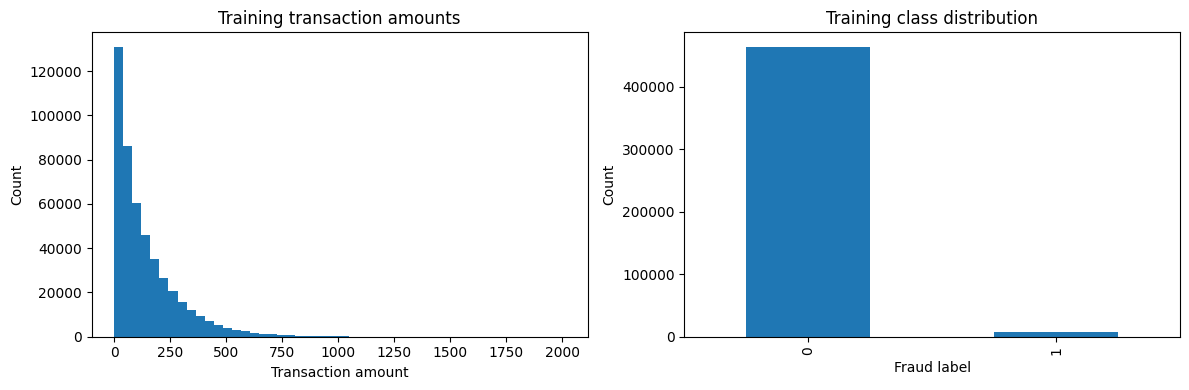

In [6]:
training_missing = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_percent": X_train.isna().mean() * 100,
})
display(training_missing.sort_values("missing_count", ascending=False))
display(train_df.groupby("isFraud")["transactionAmount"].describe())
display(train_df.groupby("cardPresent")["isFraud"].agg(["size", "mean"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df["transactionAmount"].dropna(), bins=50)
axes[0].set(title="Training transaction amounts", xlabel="Transaction amount", ylabel="Count")
train_df["isFraud"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title="Training class distribution", xlabel="Fraud label", ylabel="Count")
plt.tight_layout()
plt.show()

## 5. Fold-specific preprocessing and undersampling
For each expanding time fold, retain all fraud samples and an equal random number of legitimate samples in its training subset. Fit categorical mode imputation and one-hot encoding, numeric median imputation and scaling, and binary mode imputation on that sampled subset only. Validation remains at its natural fraud prevalence.

Transformed folds are cached and shared across candidates. This is safe here because preprocessing settings are fixed and fitted independently within each fold. Undersampling discards information and changes the class prior; it has not been shown superior to full-data weighting in this experiment.

In [7]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]),
            cat_features,
        ),
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            num_features,
        ),
        (
            "binary",
            SimpleImputer(strategy="most_frequent"),
            binary_features,
        ),
    ],
    remainder="drop",
)

In [8]:
# Start with the original training period before undersampling.
X_search = X_train[features].copy().reset_index(drop=True)
y_search = y_train.copy().reset_index(drop=True)
train_times = train_times.reset_index(drop=True)

assert len(X_search) == len(y_search) == len(train_times)
assert train_times.is_monotonic_increasing
assert train_times.notna().all()

# Group identical timestamps to prevent overlap across fold boundaries.
time_codes, unique_times = pd.factorize(train_times, sort=True)

time_cv = TimeSeriesSplit(n_splits=3)

fold_cache = []
fold_summary = []

for fold, (train_time_idx, valid_time_idx) in enumerate(
    time_cv.split(unique_times), start=1
):
    # Map timestamp-group indices back to transaction rows.
    train_idx = np.flatnonzero(
        (time_codes >= train_time_idx[0])
        & (time_codes <= train_time_idx[-1])
    )

    valid_idx = np.flatnonzero(
        (time_codes >= valid_time_idx[0])
        & (time_codes <= valid_time_idx[-1])
    )

    X_fold_train = X_search.iloc[train_idx]
    y_fold_train = y_search.iloc[train_idx]

    X_fold_valid = X_search.iloc[valid_idx]
    y_fold_valid = y_search.iloc[valid_idx]

    assert (
        train_times.iloc[train_idx].max()
        < train_times.iloc[valid_idx].min()
    )

    if y_fold_train.nunique() != 2 or y_fold_valid.nunique() != 2:
        raise ValueError(f"Fold {fold} must contain both legitimate and fraudulent transactions.")

    # Undersample only the training subset of this fold.
    sampler = RandomUnderSampler(random_state=SEED)

    X_fold_sampled, y_fold_sampled = sampler.fit_resample(
        X_fold_train,
        y_fold_train,
    )

    # Fit a fresh preprocessing pipeline for each fold.
    fold_preprocessor = clone(preprocessor)

    X_fold_sampled_t = fold_preprocessor.fit_transform(
        X_fold_sampled
    )

    # Transform fold validation data without refitting.
    X_fold_valid_t = fold_preprocessor.transform(
        X_fold_valid
    )

    # Cache transformed folds for fair, efficient candidate comparisons.
    fold_cache.append({
        "fold": fold,
        "X_train": X_fold_sampled_t,
        "y_train": np.asarray(y_fold_sampled),
        "X_valid": X_fold_valid_t,
        "y_valid": np.asarray(y_fold_valid),
    })

    fold_summary.append({
        "fold": fold,
        "train_original_n": len(train_idx),
        "train_sampled_n": len(y_fold_sampled),
        "train_fraud_n": int(y_fold_train.sum()),
        "valid_n": len(valid_idx),
        "valid_fraud_n": int(y_fold_valid.sum()),
        "valid_fraud_rate": y_fold_valid.mean(),
        "encoded_features": X_fold_sampled_t.shape[1],
        "train_start": train_times.iloc[train_idx].min(),
        "train_end": train_times.iloc[train_idx].max(),
        "valid_start": train_times.iloc[valid_idx].min(),
        "valid_end": train_times.iloc[valid_idx].max(),
    })

    print(f"Fold {fold} prepared.")

fold_summary = pd.DataFrame(fold_summary)

print(
    fold_summary[
        [
            "fold",
            "train_original_n",
            "train_sampled_n",
            "train_fraud_n",
            "valid_n",
            "valid_fraud_n",
            "valid_fraud_rate",
            "encoded_features",
        ]
    ].to_string(index=False)
)

print("\nTime boundaries:")
print(
    fold_summary[
        ["fold", "train_start", "train_end", "valid_start", "valid_end"]
    ].to_string(index=False)
)

C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


Fold 1 prepared.


C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


Fold 2 prepared.


C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


Fold 3 prepared.
 fold  train_original_n  train_sampled_n  train_fraud_n  valid_n  valid_fraud_n  valid_fraud_rate  encoded_features
    1            117880             4102           2051   117997           1912          0.016204                44
    2            235877             7926           3963   117969           1896          0.016072                45
    3            353846            11718           5859   117971           1894          0.016055                45

Time boundaries:
 fold         train_start           train_end         valid_start           valid_end
    1 2016-01-01 00:01:02 2016-02-28 15:05:20 2016-02-28 15:05:22 2016-04-25 13:37:50
    2 2016-01-01 00:01:02 2016-04-25 13:37:50 2016-04-25 13:38:29 2016-06-19 23:35:12
    3 2016-01-01 00:01:02 2016-06-19 23:35:12 2016-06-19 23:36:24 2016-08-13 06:55:08


## 6. Evaluation at a fixed 5% review budget
For N transactions, review `ceil(0.05 * N)` highest scores. Stable sorting breaks score ties by chronological row order. Precision measures review yield, recall measures fraud coverage, and lift is precision divided by the dataset fraud rate. On the same dataset and at the same review count, precision and recall rank models identically.

The 5% capacity is an illustrative operating assumption, not an empirically optimized business capacity. Scores are used for ranking and are not established as calibrated population probabilities.

In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score

REVIEW_BUDGET = 0.05

def evaluate_scores(y_true, scores, budget=REVIEW_BUDGET):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)

    assert len(y_true) == len(scores)
    assert np.isfinite(scores).all()

    review_count = max(1, int(np.ceil(len(y_true) * budget)))

    # Break score ties using the existing chronological row order.
    selected = np.argsort(-scores, kind="stable")[:review_count]

    fraud_caught = int(y_true[selected].sum())
    total_fraud = int(y_true.sum())

    precision = fraud_caught / review_count
    recall = fraud_caught / total_fraud
    base_rate = y_true.mean()

    return {
        "roc_auc": roc_auc_score(y_true, scores),
        "ap": average_precision_score(y_true, scores),
        "review_count": review_count,
        "fraud_caught": fraud_caught,
        "precision_at_5pct": precision,
        "recall_at_5pct": recall,
        "lift_at_5pct": precision / base_rate,
    }

## 7. Hyperparameter candidate grids and randomized search
Candidate zero is the baseline. Candidate budgets include that baseline. `ParameterSampler` draws reproducible configurations from the grids below using seed 42. All six logistic-regression C values are covered; tree grids are sampled rather than exhausted.

The selection objective is the equally weighted mean Recall@5% across three folds, with mean average precision (AP) as a tiebreaker. Tree count is searched directly. XGBoost's `eval_metric="logloss"` does not change the search selection objective.

In [10]:
from sklearn.model_selection import ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

model_specs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            penalty="l2",
            solver="lbfgs",
            max_iter=3000,
            random_state=SEED,
        ),
        "baseline": {
            "C": 1.0,
        },
        "space": {
            "C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
        },
        "n_candidates": 6,
    },

    "Decision Tree": {
        "estimator": DecisionTreeClassifier(
            random_state=SEED,
        ),
        "baseline": {
            "max_depth": 7,
            "min_samples_leaf": 5,
            "min_samples_split": 2,
        },
        "space": {
            "max_depth": [3, 5, 7, 10],
            "min_samples_leaf": [5, 20, 50, 100],
            "min_samples_split": [2, 10, 30],
        },
        "n_candidates": 6,
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            bootstrap=True,
            random_state=SEED,
            n_jobs=-1,
        ),
        "baseline": {
            "n_estimators": 200,
            "max_depth": 5,
            "min_samples_leaf": 4,
            "min_samples_split": 10,
            "max_features": "sqrt",
        },
        "space": {
            "n_estimators": [200, 400],
            "max_depth": [5, 10, 15, None],
            "min_samples_leaf": [2, 4, 10, 20],
            "min_samples_split": [2, 10],
            "max_features": ["sqrt", 0.7],
        },
        "n_candidates": 8,
    },

    "XGBoost": {
        "estimator": XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=SEED,
            n_jobs=4,
        ),
        "baseline": {
            "n_estimators": 150,
            "max_depth": 5,
            "learning_rate": 0.1,
            "subsample": 0.8,
            "colsample_bytree": 1.0,
            "min_child_weight": 1,
            "reg_lambda": 1.0,
            "reg_alpha": 0.0,
        },
        "space": {
            "n_estimators": [150, 300, 500],
            "max_depth": [3, 5, 7],
            "learning_rate": [0.03, 0.05, 0.1],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 1.0],
            "min_child_weight": [1, 5, 10],
            "reg_lambda": [1.0, 5.0, 10.0],
            "reg_alpha": [0.0, 0.5],
        },
        "n_candidates": 10,
    },
}


def make_candidates(spec):
    candidates = [spec["baseline"].copy()]

    sampled = list(ParameterSampler(
        spec["space"],
        n_iter=spec["n_candidates"],
        random_state=SEED,
    ))

    for params in sampled:
        if params not in candidates:
            candidates.append(params)

        if len(candidates) >= spec["n_candidates"]:
            break

    return candidates

In [11]:
search_rows = []
fold_rows = []
candidate_lookup = {}

for model_name, spec in model_specs.items():
    candidates = make_candidates(spec)

    print(
        f"\n===== {model_name}: {len(candidates)} candidates =====",
        flush=True,
    )

    for candidate_id, params in enumerate(candidates):
        candidate_lookup[(model_name, candidate_id)] = params.copy()
        fold_metrics = []

        for data in fold_cache:
            model = clone(spec["estimator"]).set_params(**params)

            model.fit(data["X_train"], data["y_train"])

            scores = model.predict_proba(data["X_valid"])[:, 1]
            metrics = evaluate_scores(data["y_valid"], scores)

            fold_metrics.append(metrics)

            fold_rows.append({
                "model": model_name,
                "candidate_id": candidate_id,
                "fold": data["fold"],
                **metrics,
            })

        recalls = [m["recall_at_5pct"] for m in fold_metrics]

        search_rows.append({
            "model": model_name,
            "candidate_id": candidate_id,
            "is_original_config": candidate_id == 0,
            "params": params.copy(),
            "mean_recall_at_5pct": np.mean(recalls),
            "std_recall_at_5pct": np.std(recalls, ddof=1),
            "mean_ap": np.mean([m["ap"] for m in fold_metrics]),
            "mean_roc_auc": np.mean([
                m["roc_auc"] for m in fold_metrics
            ]),
        })

        current = search_rows[-1]

        print(
            f"Candidate {candidate_id + 1}/{len(candidates)} | "
            f"Recall@5%={current['mean_recall_at_5pct']:.4f} | "
            f"AP={current['mean_ap']:.4f} | "
            f"AUC={current['mean_roc_auc']:.4f}",
            flush=True,
        )

    # Checkpoint search results after each model family.
    pd.DataFrame(search_rows).to_csv(
        "hyperparameter_search_results.csv", index=False
    )
    pd.DataFrame(fold_rows).to_csv(
        "hyperparameter_search_folds.csv", index=False
    )

search_results = pd.DataFrame(search_rows)
cv_fold_results = pd.DataFrame(fold_rows)

# Select by mean Recall@5%, using mean AP to break ties.
ranked_results = search_results.sort_values(
    ["model", "mean_recall_at_5pct", "mean_ap", "candidate_id"],
    ascending=[True, False, False, True],
)

best_cv = (
    ranked_results.groupby("model", sort=False)
    .head(1)
    .reset_index(drop=True)
)


===== Logistic Regression: 6 candidates =====
Candidate 1/6 | Recall@5%=0.2178 | AP=0.0507 | AUC=0.7416
Candidate 2/6 | Recall@5%=0.1901 | AP=0.0446 | AUC=0.7205
Candidate 3/6 | Recall@5%=0.2117 | AP=0.0487 | AUC=0.7293
Candidate 4/6 | Recall@5%=0.2189 | AP=0.0505 | AUC=0.7386
Candidate 5/6 | Recall@5%=0.2180 | AP=0.0508 | AUC=0.7420
Candidate 6/6 | Recall@5%=0.2182 | AP=0.0508 | AUC=0.7421

===== Decision Tree: 6 candidates =====
Candidate 1/6 | Recall@5%=0.1797 | AP=0.0405 | AUC=0.7197
Candidate 2/6 | Recall@5%=0.1946 | AP=0.0428 | AUC=0.7219
Candidate 3/6 | Recall@5%=0.1674 | AP=0.0383 | AUC=0.7041
Candidate 4/6 | Recall@5%=0.1955 | AP=0.0424 | AUC=0.7208
Candidate 5/6 | Recall@5%=0.1859 | AP=0.0427 | AUC=0.7141
Candidate 6/6 | Recall@5%=0.1284 | AP=0.0335 | AUC=0.6960

===== Random Forest: 8 candidates =====
Candidate 1/8 | Recall@5%=0.2122 | AP=0.0502 | AUC=0.7402
Candidate 2/8 | Recall@5%=0.2158 | AP=0.0496 | AUC=0.7457
Candidate 3/8 | Recall@5%=0.2208 | AP=0.0519 | AUC=0.7487
C

In [12]:
summary_columns = [
    "model",
    "candidate_id",
    "mean_recall_at_5pct",
    "std_recall_at_5pct",
    "mean_ap",
    "mean_roc_auc",
]

print("\nOriginal configurations — time CV:")
print(
    search_results.loc[
        search_results["is_original_config"],
        summary_columns,
    ].round(4).to_string(index=False)
)

print("\nBest configurations — time CV:")
print(
    best_cv[summary_columns]
    .round(4)
    .to_string(index=False)
)

print("\nSelected hyperparameters:")
for _, row in best_cv.iterrows():
    print(f"\n{row['model']}:")
    print(row["params"])

print("\nFold results for selected configurations:")
best_fold_results = cv_fold_results.merge(
    best_cv[["model", "candidate_id"]],
    on=["model", "candidate_id"],
    how="inner",
)

print(
    best_fold_results[
        ["model", "fold", "recall_at_5pct", "ap", "roc_auc"]
    ].round(4).to_string(index=False)
)


Original configurations — time CV:
              model  candidate_id  mean_recall_at_5pct  std_recall_at_5pct  mean_ap  mean_roc_auc
Logistic Regression             0               0.2178              0.0121   0.0507        0.7416
      Decision Tree             0               0.1797              0.0411   0.0405        0.7197
      Random Forest             0               0.2122              0.0052   0.0502        0.7402
            XGBoost             0               0.2174              0.0236   0.0533        0.7577

Best configurations — time CV:
              model  candidate_id  mean_recall_at_5pct  std_recall_at_5pct  mean_ap  mean_roc_auc
      Decision Tree             3               0.1955              0.0298   0.0424        0.7208
Logistic Regression             3               0.2189              0.0158   0.0505        0.7386
      Random Forest             7               0.2284              0.0100   0.0524        0.7554
            XGBoost             4               0.

## 8. Refit and compare on outer validation
Refit selected configurations using the same full-training balanced sample (7,753 fraud and 7,753 legitimate transactions in the recorded run). The original outer training period contains 471,817 transactions; it includes the last internal validation window after cross-validation is complete.

Rank model families by validation Recall@5%, using AP as a tiebreaker. Fold standard deviations summarize three time periods and are not confidence intervals.

In [13]:
X_validation = X_valid[features].copy().reset_index(drop=True)
y_validation = np.asarray(y_valid, dtype=int)

final_sampler = RandomUnderSampler(random_state=SEED)

X_train_sampled, y_train_sampled = final_sampler.fit_resample(
    X_search,
    y_search,
)

print("Sampled training size:", len(y_train_sampled))
print(pd.Series(y_train_sampled).value_counts().sort_index())

Sampled training size: 15506
isFraud
0    7753
1    7753
Name: count, dtype: int64


C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\82434\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [14]:
tuned_models = {}
tuned_validation_scores = {}
validation_rows = []

for _, row in best_cv.iterrows():
    model_name = row["model"]
    candidate_id = int(row["candidate_id"])

    selected_params = candidate_lookup[
        (model_name, candidate_id)
    ].copy()

    estimator = clone(
        model_specs[model_name]["estimator"]
    ).set_params(**selected_params)

    # Use an independent preprocessing pipeline for each model.
    model_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator),
    ])

    print(f"\nTraining: {model_name}", flush=True)
    print("Selected parameters:", selected_params)

    # Fit imputation, encoding, and scaling only on sampled training data.
    model_pipeline.fit(
        X_train_sampled,
        y_train_sampled,
    )

    # The outer validation period is never used for fitting.
    valid_scores = model_pipeline.predict_proba(
        X_validation
    )[:, 1]

    metrics = evaluate_scores(
        y_validation,
        valid_scores,
    )

    tuned_models[model_name] = model_pipeline
    tuned_validation_scores[model_name] = valid_scores

    validation_rows.append({
        "model": model_name,
        **metrics,
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values(
        ["recall_at_5pct", "ap"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

print("\nTuned models — external validation:")
print(
    validation_results.round(4).to_string(index=False)
)

validation_results.to_csv(
    "tuned_validation_results.csv",
    index=False,
)


Training: Decision Tree
Selected parameters: {'min_samples_split': 30, 'min_samples_leaf': 5, 'max_depth': 7}

Training: Logistic Regression
Selected parameters: {'C': 0.1}

Training: Random Forest
Selected parameters: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 15}

Training: XGBoost
Selected parameters: {'subsample': 0.7, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'n_estimators': 150, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Tuned models — external validation:
              model  roc_auc     ap  review_count  fraud_caught  precision_at_5pct  recall_at_5pct  lift_at_5pct
            XGBoost   0.7777 0.0553          7864           577             0.0734          0.2454        4.9083
      Random Forest   0.7784 0.0528          7864           563             0.0716          0.2395        4.7892
Logistic Regression   0.7566 0.0494          7864           521             0.0663       

## 9. Final test evaluation
In the recorded validation comparison, XGBoost ranks first on the review metric. Lock the model and 5% ranking policy before test evaluation; do not refit on combined training and validation.

**Evaluation limitation:** this test period had already been examined in earlier exploratory work. It was excluded from the present hyperparameter search, but it is not an untouched project-wide test. A fresh future period is needed for independent confirmation.

In [15]:
# Lock the selected model before evaluating the test period.
final_model_name = validation_results.iloc[0]["model"]
final_model = tuned_models[final_model_name]

X_test_final = X_test[features].copy().reset_index(drop=True)
y_test_final = np.asarray(y_test, dtype=int)

test_scores = final_model.predict_proba(X_test_final)[:, 1]

test_metrics = evaluate_scores(
    y_test_final,
    test_scores,
    budget=0.05,
)

test_results = pd.DataFrame([{
    "model": final_model_name,
    "fraud_rate": y_test_final.mean(),
    **test_metrics,
}])

print("Final model — test results:")
print(test_results.round(4).to_string(index=False))

# Build review flags using exactly the same ranking policy.
review_count = test_metrics["review_count"]
selected = np.argsort(
    -test_scores, kind="stable"
)[:review_count]

test_flagged = np.zeros(len(y_test_final), dtype=int)
test_flagged[selected] = 1

from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test_final,
    test_flagged,
    labels=[0, 1],
).ravel()

print(f"\nReviewed transactions: {review_count:,}")
print(f"Fraud caught (TP): {tp:,}")
print(f"Non-fraud flagged (FP): {fp:,}")
print(f"Fraud missed (FN): {fn:,}")
print(f"Non-fraud not flagged (TN): {tn:,}")

random_expected = review_count * y_test_final.mean()
print(
    f"Expected fraud caught by random review: "
    f"{random_expected:.1f}"
)

test_results.to_csv("tuned_xgboost_test_results.csv", index=False)

Final model — test results:
  model  fraud_rate  roc_auc     ap  review_count  fraud_caught  precision_at_5pct  recall_at_5pct  lift_at_5pct
XGBoost      0.0147    0.771 0.0535          7864           576             0.0732           0.249        4.9803

Reviewed transactions: 7,864
Fraud caught (TP): 576
Non-fraud flagged (FP): 7,288
Fraud missed (FN): 1,737
Non-fraud not flagged (TN): 147,672
Expected fraud caught by random review: 115.7


## 10. Recorded findings and next steps
The recorded final XGBoost result reviews **7,864** of **157,273** test transactions and identifies **576** of **2,313** labeled fraud cases:

| Metric | Recorded result |
|---|---:|
| Recall at 5% | 24.90% |
| Precision at 5% | 7.32% |
| Lift at 5% | 4.9803 |
| ROC-AUC | 0.7710 |
| Average precision | 0.0535 |
| Legitimate transactions flagged | 7,288 |
| Fraud cases missed | 1,737 |
| Expected fraud captured by random review | 115.7 |

These are historical offline results, not realized prevented losses. Most flagged transactions remain legitimate, so these findings support review prioritization rather than automatic rejection. The search is limited and does not establish statistical significance or global optimality.

Next steps include auditing feature and label availability at transaction time, evaluating on fresh future data, comparing class weighting against undersampling, assessing calibration if probabilities are needed, and incorporating review costs, customer friction, segment performance, and drift monitoring.

The CSV files generated during execution contain aggregate search and evaluation results. Avoid committing source transaction files or transaction-level exports to the repository.